# Which ECGs create our condition keys?

KEY-03 · Training-reference audit · 6 November 2026

This notebook examines the ECGs actually averaged in KEY-01 and KEY-02. It covers reference
composition, annotation overlap, repeated patients, source effects, embedding geometry and region
selection. The companion local waveform notebook and PDF contain twenty prespecified review
panels. Individual waveform panels and record mappings remain in ignored local outputs.

A key averages **standardized, unit-normalized embedding vectors**, not raw ECG voltages.
Each reference record has equal weight. A nearest reference is an example selected by the model's
geometry, not a clinician-approved typical case. These groups are overlapping annotation proxies.


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd()
if not (ROOT / 'ecg_experiment').exists():
    ROOT = ROOT.parent
r = json.loads((ROOT / 'reports/reference-ecg-audit-2026-11-06/aggregate.json').read_text())
assert r['status'] == 'completed'
groups = ['MI', 'STTC', 'CD', 'HYP']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('Study:', r['study'], '| Source:', r['git_commit'])
print('Saved predecessor metric dictionaries reproduced:', r['metric_dictionaries_reproduced'])
print('New evaluation scores:', r['new_evaluation_scores'])


Study: KEY-03 | Source: 438adfbce29a6f5aa279fe1edb577e80b15bf23d
Saved predecessor metric dictionaries reproduced: 24
New evaluation scores: False


## 1. Population and what is known about its labels

All 25,000 reference records are from permitted training roles. SPH contributes no references.
Source-level physician-reading processes and individual human-validation fields are different
kinds of evidence. A missing per-record validation field does not establish that a label came
from software. The counts below preserve that distinction.

Patient identity is known only where the source supplies it. Unknown identities are not converted
into a claimed number of unique people. Exact signal-hash duplicates are a narrow duplication
check: absence of equal hashes cannot exclude near-duplicates or repeated patients.


In [2]:
overall = r['overall']
display(pd.Series({k: v for k, v in overall.items() if not isinstance(v, dict)}, name='count').to_frame())
display(pd.Series(overall['label_evidence'], name='records').to_frame())
validation = pd.Series(overall['individual_human_validation'], name='records')
display(validation.rename(index={'': 'unavailable'}).to_frame())
review = pd.Series(overall['review_flags'], name='records')
display(review.rename(index={'': 'no recorded review flag'}).to_frame())


,count
records,25000
known_identity_records,6828
known_patients,6359
unknown_identity_records,18172
known_patient_extra_record_count,469
duplicate_canonical_records,0
duplicate_full_signal_records,0


,records
source_process_physician_label_secondary_validation_senior_adjudication,13002
record_human_validated,6828
human_overread_source_no_per_record_reader_count_proof,3974
human_read_source_no_per_record_reader_count_proof,1196


,records
unavailable,18172
True,6828


,records
no recorded review flag,24849
amplitude_over_10mv,148
strong_baseline_wander,3


## 2. Which sources contribute to each average?

The four positive pools overlap. Normal references are the shared negative pool under the frozen
binary definition; they are not newly certified clinically normal. The number of records from each
family is its literal contribution to the arithmetic average before normalization. The direction
of its contribution also depends on its vectors, examined later.


,ptbxl,cpsc,chapman_ningbo,georgia,total
MI,1626,290,122,3,2041
STTC,1789,418,7872,2277,12356
CD,1537,488,3025,999,6049
HYP,843,32,465,1036,2376
normal,3038,154,3400,801,7393


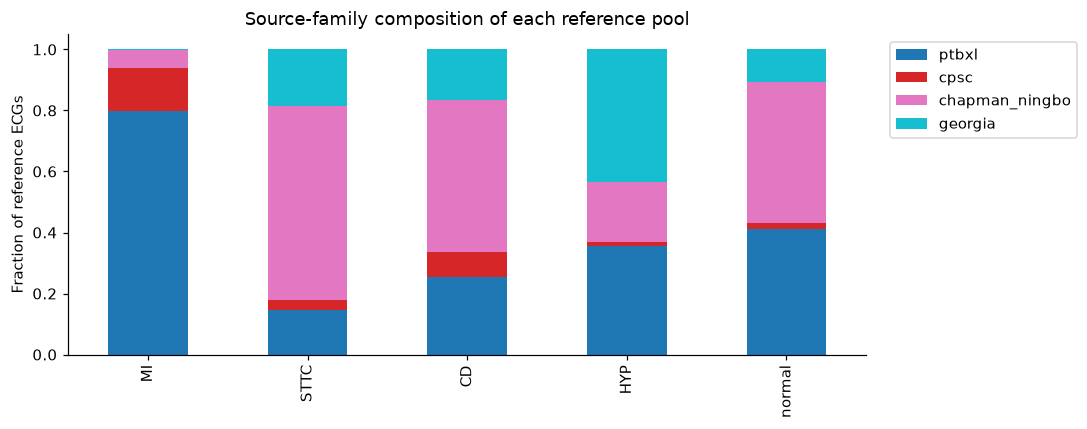

,records,known_patients,known_identity_records,unknown_identity_records,known_patient_extra_record_count
MI,2041,1501,1626,415,125
STTC,12356,1662,1789,10567,127
CD,6049,1428,1537,4512,109
HYP,2376,809,843,1533,34
normal,7393,2941,3038,4355,97


In [3]:

composition = pd.DataFrame({g: v['families'] for g, v in r['composition'].items()}).fillna(0).astype(int).T
composition['total'] = composition.sum(axis=1)
display(composition)
shares = composition.drop(columns='total').div(composition['total'], axis=0)
shares.plot.bar(stacked=True, figsize=(10, 4), colormap='tab10')
plt.ylabel('Fraction of reference ECGs')
plt.title('Source-family composition of each reference pool')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()
identity = pd.DataFrame({g: {k: v[k] for k in ['records', 'known_patients',
    'known_identity_records', 'unknown_identity_records', 'known_patient_extra_record_count']}
    for g, v in r['composition'].items()}).T
display(identity)


## 3. Averaging mixed annotations

A vector can contribute to several condition keys. The diagonal below is each positive reference
count; off-diagonal entries count shared reference ECGs. Row-normalized values answer: among
references for this row's group, what fraction also carries the column's group? This is annotation
co-occurrence in the support cohort, not population disease prevalence or causation.


,MI,STTC,CD,HYP
MI,2041,686,663,285
STTC,686,12356,2265,1470
CD,663,2265,6049,583
HYP,285,1470,583,2376


,positive references,exclusive group references
MI,2041,812
STTC,12356,8578
CD,6049,3084
HYP,2376,593


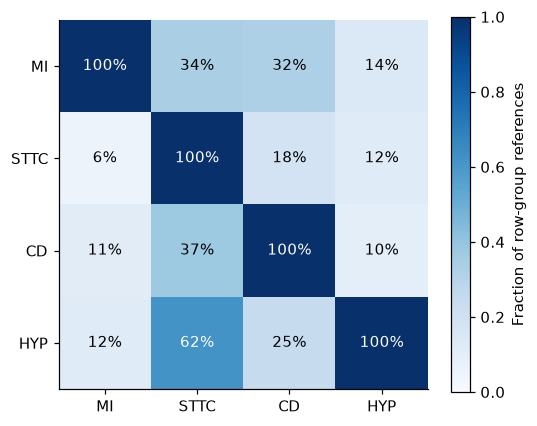

In [4]:
co = np.asarray(r['cooccurrence'])
assert np.array_equal(co, co.T)
display(pd.DataFrame(co, index=groups, columns=groups))
display(pd.DataFrame({'positive references': np.diag(co),
    'exclusive group references': [r['exclusive_counts'][g] for g in groups]}, index=groups))
conditional = co / np.diag(co)[:, None]
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(conditional, vmin=0, vmax=1, cmap='Blues')
ax.set(xticks=range(4), yticks=range(4), xticklabels=groups, yticklabels=groups)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f'{conditional[i,j]:.0%}', ha='center', va='center',
                color='white' if conditional[i,j] > .6 else 'black')
fig.colorbar(im, ax=ax, label='Fraction of row-group references')
plt.tight_layout()
plt.show()


## 4. Reconstruction and compactness of the averages

Every positive and class-specific normal key is reconstructed directly from the original vectors
and saved window selections. Maximum coordinate error must be at most 1e-12, allowing only
summation-order differences. Selected references are not reselected in this audit.

Resultant length is the norm of the mean of unit vectors: values near one indicate stronger
alignment, while small values indicate cancellation. It describes support geometry; it is not
classification accuracy. Selecting regions to maximize training margins can create compact
reference directions without improving external ranking.


Key reconstruction errors: {'whole': 5.759281940243e-16, 'short': 0.0, 'fixed_1s': 0.0, '2.5s': 0.0, '5s': 0.0, '7.5s': 0.0}


arm,2.5s,5s,7.5s,fixed_1s,short,whole
key,,,,,,
normal_CD,0.4463,0.4202,0.4072,0.4322,0.4836,0.3859
normal_HYP,0.4284,0.4107,0.4019,0.4196,0.4513,0.3859
normal_MI,0.4397,0.4148,0.4034,0.4331,0.4973,0.3859
normal_STTC,0.4264,0.4122,0.4035,0.3965,0.4328,0.3859
positive_CD,0.2659,0.2418,0.2340,0.2895,0.3364,0.2295
positive_HYP,0.2407,0.2164,0.2013,0.2664,0.3056,0.1865
positive_MI,0.3024,0.2608,0.2428,0.3408,0.4193,0.2285
positive_STTC,0.1958,0.1749,0.1649,0.2170,0.2657,0.1552


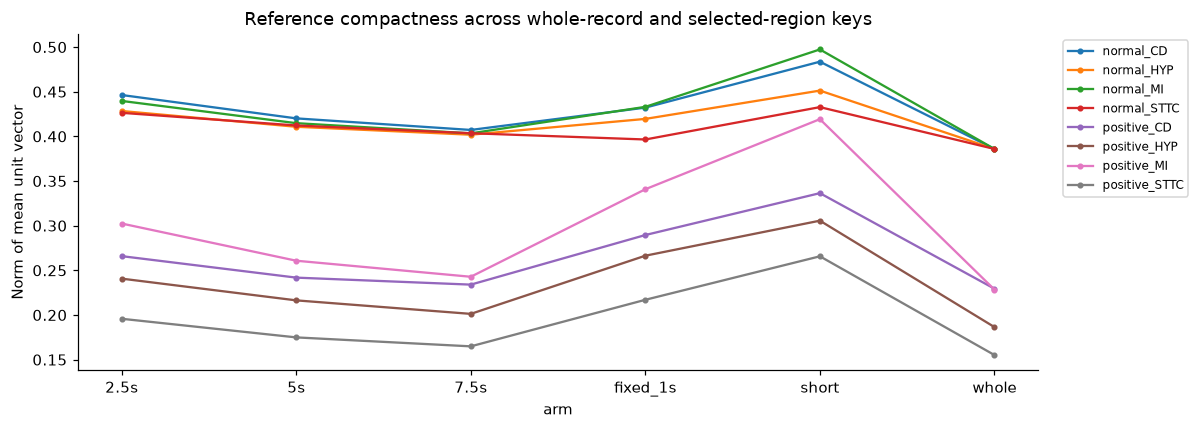

In [5]:
print('Key reconstruction errors:', {a: v['key_max_error'] for a, v in r['geometry'].items()})
geometry = pd.DataFrame([{'arm': a, 'key': g, **v}
    for a, details in r['geometry'].items() for g, v in details['groups'].items()])
coherence = geometry.pivot(index='key', columns='arm', values='resultant_length')
display(coherence.style.format('{:.4f}'))
coherence.T.plot(figsize=(11, 4), marker='o', markersize=3)
plt.ylabel('Norm of mean unit vector')
plt.title('Reference compactness across whole-record and selected-region keys')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()


## 5. How far do region keys rotate?

The angle below compares each key to its corresponding whole-record key. Normal-region keys
are class-specific after selection even though they use the same normal records. Consequently,
positive-key changes alone cannot explain a positive-minus-normal similarity score.


arm,2.5s,5s,7.5s,fixed_1s,short,whole
key,,,,,,
normal_CD,26.31,18.13,13.43,33.29,35.42,0.00
normal_HYP,22.61,14.86,10.73,32.07,30.43,0.00
normal_MI,25.74,16.52,11.53,34.64,39.71,0.00
normal_STTC,19.98,14.11,10.81,24.10,23.62,0.00
positive_CD,23.31,13.17,9.56,33.07,38.96,0.00
positive_HYP,34.46,26.00,18.77,43.58,47.84,0.00
positive_MI,29.69,19.39,13.64,39.21,45.72,0.00
positive_STTC,29.16,20.87,16.00,39.12,44.67,0.00


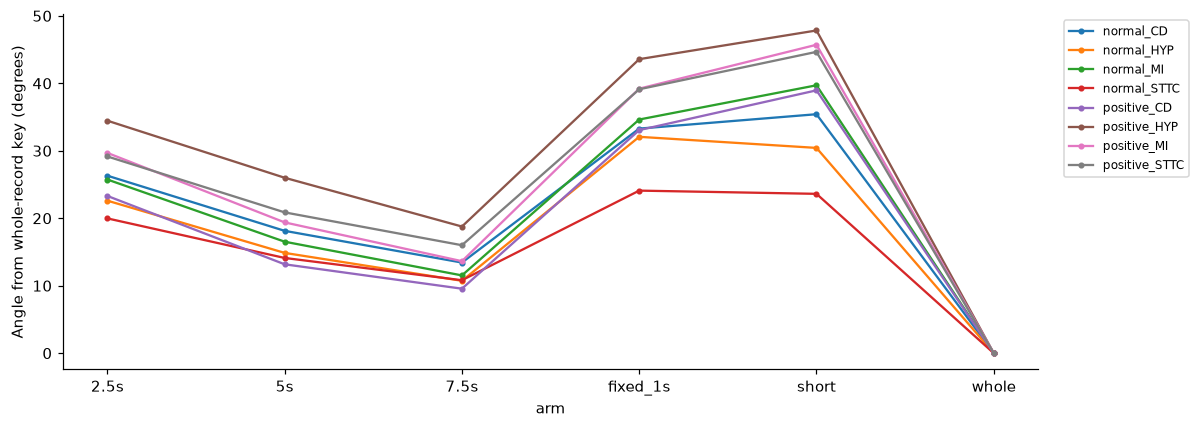

In [6]:
rotation = geometry.pivot(index='key', columns='arm', values='whole_key_rotation_degrees')
display(rotation.style.format('{:.2f}'))
rotation.T.plot(figsize=(11, 4), marker='o', markersize=3)
plt.ylabel('Angle from whole-record key (degrees)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()


## 6. Source removal and known-patient weighting

Source-removed rotation is a geometric sensitivity check: subtract that family's vector sum and
measure the remaining key's angle from the original. It is not a retrained classifier or a hospital
transfer score. Large rotation can reflect both sample share and different recording/label patterns.

The equal-patient diagnostic gives equal weight to each known patient's mean representation;
unknown-patient records retain record weights. It cannot correct repeated patients that are not
identified by the data. No alternative weighting is promoted or evaluated on SPH.


In [7]:
removed = pd.DataFrame([{'arm': a, 'key': g, **v['source_removed_rotation_degrees']}
    for a, details in r['geometry'].items() for g, v in details['groups'].items()]).set_index(['arm', 'key'])
display(removed.loc[['whole', 'short', '5s', '7.5s']].style.format('{:.2f}'))
patient_rotation = geometry.pivot(index='key', columns='arm', values='equal_patient_rotation_degrees')
display(patient_rotation.style.format('{:.3f}'))
exclusive = geometry.pivot(index='key', columns='arm', values='exclusive_vs_cooccurring_angle_degrees')
display(exclusive.dropna(how='all').style.format('{:.2f}', na_rep='not applicable'))


arm,2.5s,5s,7.5s,fixed_1s,short,whole
key,,,,,,
normal_CD,0.361,0.407,0.428,0.340,0.300,0.458
normal_HYP,0.386,0.422,0.434,0.362,0.350,0.458
normal_MI,0.368,0.418,0.433,0.337,0.276,0.458
normal_STTC,0.373,0.417,0.430,0.364,0.353,0.458
positive_CD,0.809,0.916,0.941,0.653,0.560,0.953
positive_HYP,0.744,0.850,0.935,0.626,0.567,1.001
positive_MI,1.390,1.703,1.920,1.156,1.018,2.098
positive_STTC,0.602,0.706,0.775,0.475,0.394,0.840


arm,2.5s,5s,7.5s,fixed_1s,short,whole
key,,,,,,
positive_CD,41.94,47.77,50.23,34.12,28.08,51.71
positive_HYP,67.15,76.80,83.15,55.38,49.68,89.99
positive_MI,40.88,50.46,55.45,32.33,25.69,59.77
positive_STTC,50.19,58.33,62.82,41.42,34.44,66.62


## 7. Which ECGs are closest to a key?

The fifty highest reference-to-key cosines have the largest projections onto that key direction.
They still had the same averaging weight as other reference ECGs. Their source distribution can
be much more concentrated than the full support pool. This is why showing a handful of nearest
ECGs alone is insufficient to justify the average as representative.


In [8]:
nearest = pd.DataFrame([{'arm': a, 'key': g, **v['top50_sources']}
    for a, details in r['geometry'].items() for g, v in details['groups'].items()]).fillna(0)
display(nearest.loc[nearest['arm'].isin(['whole', 'short', '5s', '7.5s'])].set_index(['arm', 'key']))
quantiles = pd.DataFrame([{'arm': a, 'key': g,
    **dict(zip(['min', 'p05', 'p25', 'median', 'p75', 'p95', 'max'], v['cosine_quantiles']))}
    for a, details in r['geometry'].items() for g, v in details['groups'].items()])
display(quantiles.set_index(['arm', 'key']).round(3))


ptbxl  ningbo  cpsc_2018_extra  georgia  \
arm   key                                                      
whole positive_MI       45     2.0              2.0      1.0   
      positive_STTC      3    37.0              0.0      0.0   
      positive_CD       20    15.0              0.0      7.0   
      positive_HYP      13    11.0              2.0     24.0   
      normal_MI         19    25.0              0.0      0.0   
      normal_STTC       19    25.0              0.0      0.0   
      normal_CD         19    25.0              0.0      0.0   
      normal_HYP        19    25.0              0.0      0.0   
short positive_MI       49     0.0              0.0      1.0   
      positive_STTC      8    31.0              0.0      1.0   
      positive_CD       21    19.0              0.0      7.0   
      positive_HYP      30     1.0              0.0     19.0   
      normal_MI         15    27.0              0.0      2.0   
      normal_STTC       19    18.0              0.0      4.0   
      normal_CD         16    22.0              0.0      4.0   
      normal_HYP        14    26.0              0.0      1.0   
5s    positive_MI       48     1.0              0.0      1.0   
      positive_STTC      4    33.0              0.0      1.0   
      positive_CD       13    23.0              0.0      3.0   
      positive_HYP      17    10.0              1.0     22.0   
      normal_MI         16    27.0              0.0      0.0   
      normal_STTC       16    26.0              0.0      1.0   
      normal_CD         18    25.0              0.0      1.0   
      normal_HYP        15    27.0              0.0      0.0   
7.5s  positive_MI       47     1.0              1.0      1.0   
      positive_STTC      2    37.0              0.0      0.0   
      positive_CD       15    22.0              0.0      5.0   
      positive_HYP      13    10.0              2.0     25.0   
      normal_MI         19    26.0              0.0      0.0   
      normal_STTC       17    27.0              0.0      1.0   
      normal_CD         16    29.0              0.0      1.0   
      normal_HYP        18    27.0              0.0      1.0   

                     chapman_shaoxing  cpsc_2018  
arm   key                                         
whole positive_MI                 0.0        0.0  
      positive_STTC              10.0        0.0  
      positive_CD                 5.0        3.0  
      positive_HYP                0.0        0.0  
      normal_MI                   6.0        0.0  
      normal_STTC                 6.0        0.0  
      normal_CD                   6.0        0.0  
      normal_HYP                  6.0        0.0  
short positive_MI                 0.0        0.0  
      positive_STTC              10.0        0.0  
      positive_CD                 2.0        1.0  
      positive_HYP                0.0        0.0  
      normal_MI                   6.0        0.0  
      normal_STTC                 9.0        0.0  
      normal_CD                   8.0        0.0  
      normal_HYP                  9.0        0.0  
5s    positive_MI                 0.0        0.0  
      positive_STTC              12.0        0.0  
      positive_CD                 8.0        3.0  
      positive_HYP                0.0        0.0  
      normal_MI                   7.0        0.0  
      normal_STTC                 7.0        0.0  
      normal_CD                   6.0        0.0  
      normal_HYP                  8.0        0.0  
7.5s  positive_MI                 0.0        0.0  
      positive_STTC              11.0        0.0  
      positive_CD                 5.0        3.0  
      positive_HYP                0.0        0.0  
      normal_MI                   5.0        0.0  
      normal_STTC                 5.0        0.0  
      normal_CD                   4.0        0.0  
      normal_HYP                  4.0        0.0

min    p05    p25  median    p75    p95    max
arm      key                                                            
whole    positive_MI   -0.397 -0.085  0.103   0.239  0.362  0.509  0.706
         positive_STTC -0.561 -0.234  0.015   0.162  0.309  0.508  0.682
         positive_CD   -0.414 -0.085  0.102   0.241  0.370  0.509  0.699
         positive_HYP  -0.324 -0.099  0.051   0.183  0.315  0.487  0.670
         normal_MI     -0.292  0.146  0.297   0.398  0.488  0.589  0.724
         normal_STTC   -0.292  0.146  0.297   0.398  0.488  0.589  0.724
         normal_CD     -0.292  0.146  0.297   0.398  0.488  0.589  0.724
         normal_HYP    -0.292  0.146  0.297   0.398  0.488  0.589  0.724
short    positive_MI   -0.242  0.137  0.311   0.436  0.538  0.659  0.789
         positive_STTC -0.339  0.006  0.179   0.280  0.370  0.472  0.648
         positive_CD   -0.269  0.105  0.246   0.346  0.438  0.544  0.646
         positive_HYP  -0.340  0.023  0.217   0.320  0.413  0.534  0.691
         normal_MI     -0.213  0.315  0.433   0.505  0.572  0.650  0.809
         normal_STTC   -0.218  0.236  0.358   0.440  0.515  0.606  0.751
         normal_CD     -0.214  0.306  0.417   0.489  0.558  0.644  0.789
         normal_HYP    -0.209  0.249  0.375   0.458  0.535  0.632  0.792
fixed_1s positive_MI   -0.366  0.042  0.230   0.350  0.469  0.603  0.804
         positive_STTC -0.483 -0.094  0.118   0.233  0.335  0.466  0.645
         positive_CD   -0.339  0.037  0.187   0.296  0.401  0.522  0.658
         positive_HYP  -0.510 -0.072  0.165   0.286  0.395  0.532  0.661
         normal_MI     -0.233  0.194  0.347   0.444  0.531  0.632  0.769
         normal_STTC   -0.226  0.184  0.321   0.407  0.483  0.574  0.707
         normal_CD     -0.233  0.208  0.352   0.443  0.524  0.621  0.758
         normal_HYP    -0.246  0.176  0.332   0.432  0.518  0.623  0.748
2.5s     positive_MI   -0.346 -0.013  0.183   0.318  0.437  0.584  0.752
         positive_STTC -0.541 -0.176  0.076   0.210  0.338  0.500  0.666
         positive_CD   -0.412 -0.022  0.152   0.274  0.389  0.520  0.679
         positive_HYP  -0.451 -0.101  0.138   0.257  0.372  0.498  0.666
         normal_MI     -0.243  0.191  0.352   0.455  0.543  0.638  0.773
         normal_STTC   -0.227  0.196  0.346   0.440  0.521  0.616  0.737
         normal_CD     -0.234  0.208  0.362   0.461  0.545  0.637  0.794
         normal_HYP    -0.226  0.190  0.345   0.442  0.526  0.620  0.766
5s       positive_MI   -0.418 -0.064  0.138   0.276  0.391  0.554  0.722
         positive_STTC -0.563 -0.205  0.041   0.183  0.326  0.510  0.686
         positive_CD   -0.429 -0.061  0.119   0.251  0.376  0.513  0.691
         positive_HYP  -0.380 -0.090  0.101   0.224  0.346  0.486  0.665
         normal_MI     -0.245  0.163  0.322   0.429  0.521  0.623  0.757
         normal_STTC   -0.255  0.170  0.324   0.426  0.514  0.613  0.744
         normal_CD     -0.270  0.172  0.330   0.435  0.523  0.623  0.761
         normal_HYP    -0.247  0.168  0.323   0.424  0.512  0.613  0.751
7.5s     positive_MI   -0.418 -0.074  0.119   0.256  0.373  0.525  0.708
         positive_STTC -0.553 -0.211  0.029   0.170  0.317  0.511  0.664
         positive_CD   -0.394 -0.076  0.109   0.245  0.373  0.509  0.683
         positive_HYP  -0.269 -0.090  0.080   0.210  0.323  0.484  0.685
         normal_MI     -0.278  0.154  0.312   0.417  0.507  0.610  0.751
         normal_STTC   -0.284  0.161  0.314   0.417  0.504  0.607  0.744
         normal_CD     -0.290  0.161  0.316   0.421  0.509  0.609  0.746
         normal_HYP    -0.272  0.158  0.314   0.415  0.504  0.605  0.746

## 8. Where do the selected reference sections occur?

These are nominal token starts and lengths, with four tokens per second. Each token is contextual:
a selected span is not an independently encoded crop and does not locate disease. Positive
references maximize the initial margin; normal references minimize it. The two selection rules
can therefore emphasize different time positions even when there is no clinical regional truth.


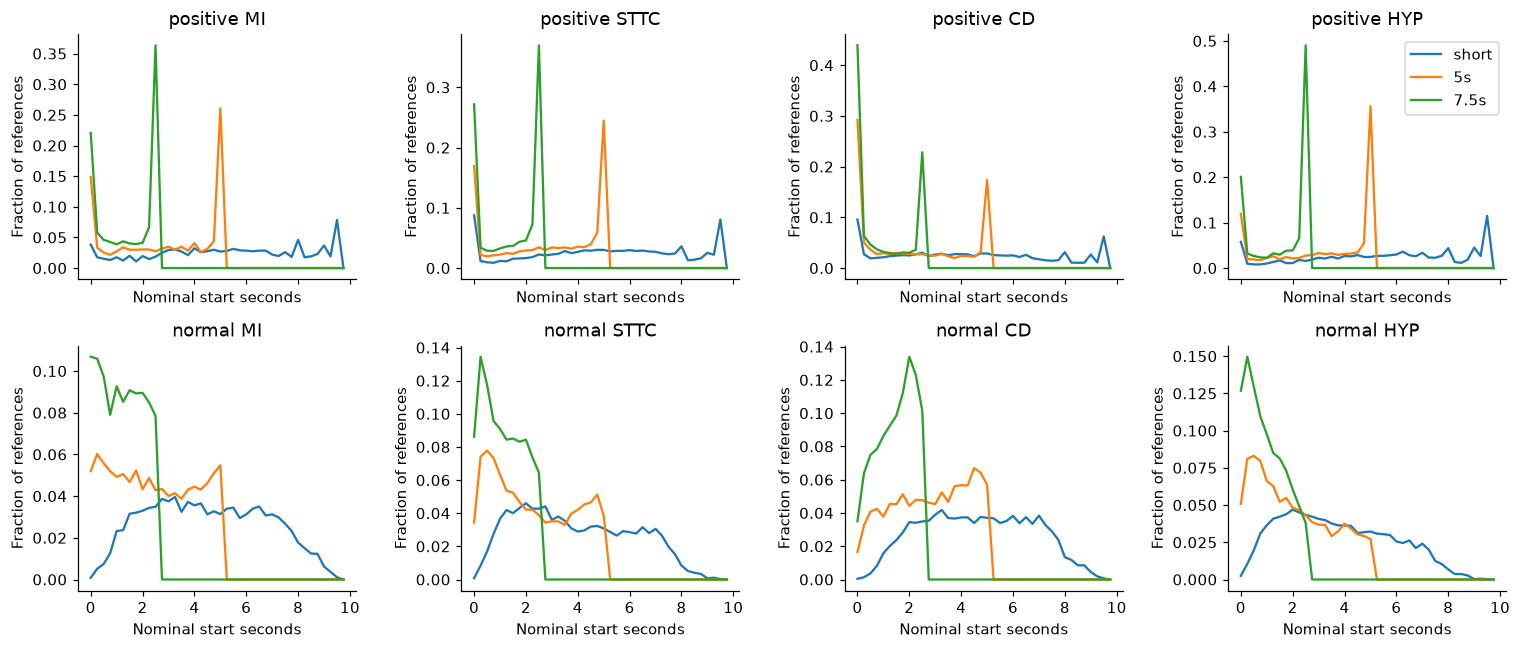

chapman_ningbo   cpsc  georgia  ptbxl
arm   key                                                 
short positive_MI             5.869  5.007    8.167  5.250
      positive_STTC           5.085  4.218    5.056  5.066
      positive_CD             4.409  3.766    4.411  4.219
      positive_HYP            5.363  5.680    5.742  5.505
      normal_MI               4.373  4.209    4.542  4.692
      normal_STTC             3.826  3.786    3.879  4.001
      normal_CD               4.532  4.657    4.629  4.723
      normal_HYP              3.664  3.456    3.758  3.764
5s    positive_MI             3.123  2.698    4.000  2.847
      positive_STTC           2.932  2.514    2.805  2.844
      positive_CD             2.128  1.596    2.152  2.166
      positive_HYP            3.265  2.961    3.330  3.207
      normal_MI               2.345  2.114    2.393  2.518
      normal_STTC             2.230  2.057    2.240  2.322
      normal_CD               2.786  2.657    2.766  2.817
      normal_HYP              1.976  1.688    1.927  2.097
7.5s  positive_MI             1.662  1.338    2.500  1.430
      positive_STTC           1.472  1.164    1.378  1.394
      positive_CD             0.951  0.621    0.993  0.995
      positive_HYP            1.712  1.500    1.695  1.604
      normal_MI               1.153  1.086    1.186  1.244
      normal_STTC             1.100  1.062    1.150  1.161
      normal_CD               1.430  1.477    1.490  1.476
      normal_HYP              0.935  0.883    0.944  1.007

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex=True)
for row, kind in enumerate(['positive', 'normal']):
    for col, group in enumerate(groups):
        ax = axes[row, col]
        for arm in ['short', '5s', '7.5s']:
            v = r['geometry'][arm]['groups'][kind + '_' + group]
            ax.plot(np.arange(40)/4, np.asarray(v['start_counts'])/v['records'], label=arm)
        ax.set(title=kind + ' ' + group, xlabel='Nominal start seconds', ylabel='Fraction of references')
axes[0, -1].legend()
plt.tight_layout()
plt.show()
source_starts = pd.DataFrame([{'arm': a, 'key': g, **v.get('source_mean_start_seconds', {})}
    for a, details in r['geometry'].items() if a != 'whole'
    for g, v in details['groups'].items()]).set_index(['arm', 'key'])
display(source_starts.loc[['short', '5s', '7.5s']].round(3))


## 9. Inspecting actual training waveforms

Four roles per group and the normal pool were fixed before selection: nearest to the whole key
within each of the two largest source families; least similar to the whole key; largest vector
change after short-section selection. Repeated ECGs are loaded once, but all twenty review roles
are retained. The normal change example uses the MI-specific normal selection.

Each lead uses its own vertical axis limits; compare the numeric mV ticks rather than apparent
trace heights across leads. These are scientific plots, not a calibrated ECG-paper layout.

Each waveform is checked against raw-file and canonical-signal hashes by the existing training
loader. The private atlas plots all twelve leads in mV with nominal short, five- and 7.5-second
selection bars. Labels are existing annotations, not a new reading. Finite/flat-lead observations
are descriptive quality checks and cannot certify clinical validity.

Local artifacts:
- `outputs/reference_ecg_audit_20261106/ReferenceECGAtlas.pdf`
- `outputs/reference_ecg_audit_20261106/ReferenceWaveforms.ipynb`

Individual waveform images and original record mappings are deliberately kept out of the aggregate
Git notebook. These can be reviewed locally with the cardiologist without changing the frozen labels.


In [10]:
display(pd.Series(r['waveform_review'], name='executed waveform review').to_frame())
checks = 0
for group, values in r['composition'].items():
    assert sum(values['sources'].values()) == values['records']
    assert sum(values['families'].values()) == values['records']
    assert values['known_identity_records'] + values['unknown_identity_records'] == values['records']
    checks += 3
for arm, details in r['geometry'].items():
    assert details['key_max_error'] <= 1e-12
    checks += 1
    for key, values in details['groups'].items():
        assert sum(values['top50_sources'].values()) == 50
        checks += 1
        if 'start_counts' in values:
            assert sum(values['start_counts']) == values['records']
            assert sum(values['length_counts'].values()) == values['records']
            checks += 2
assert np.array_equal(co, co.T)
checks += 1
print('Aggregate consistency checks passed:', checks)
print('Clinical adjudication performed:', r['clinical_review_performed'])


,executed waveform review
panels,20
unique_waveforms,20
all_finite,True
panels_with_flat_leads,0


Aggregate consistency checks passed: 150
Clinical adjudication performed: False


## Observed patterns in these references

The MI support pool is 79.7% PTB-XL, and 45 of its 50 nearest whole-key references are PTB-XL.
The STTC pool is 63.7% Chapman/Ningbo, with 47 of its 50 nearest references from that family.
Removing these families rotates the respective whole keys by about 46 and 61 degrees.
These geometry shifts combine sample-share, acquisition and annotation differences; they do not
isolate a hospital artifact or prove that source balancing would improve prediction.

Only 812 of 2,041 MI references and 593 of 2,376 HYP references carry their group exclusively.
Thus about 60% of MI and 75% of HYP references also contribute other abnormal annotations.
The keys summarize mixtures of findings, not isolated examples of one disease.

Short selection increases positive-reference coherence but rotates their keys by roughly 39–48
degrees. Five- and 7.5-second keys rotate less. Together with KEY-01/02's measured performance,
this shows that a more tightly aligned training reference bank can transfer worse. The cause is
not established by these descriptive comparisons.

Among identified PTB patients, record repetition accounts for 469 extra records across the full
cohort. Equal-known-patient weighting rotates whole keys by about 0.5–2.1 degrees. That limited
check is much smaller than dominant-source removal, but 18,172 records lack patient identity.
It cannot rule out repeated-patient effects in those sources.

All twenty sampled waveforms were finite and had no flat lead. That does not establish freedom
from noise or drift. In the local atlas, Reference 16 shows a pronounced slow V4 level shift and
its short selected window covers the initial half-second. Its existing review-flag field is empty.
This visual observation is post hoc, warrants quality review, and does not prove why its key moved.
It is not a new diagnosis or an automatically applied exclusion.


## Interpretation and reproduction

This is a descriptive audit of fixed reference averages. Geometry shifts and source concentration
can motivate follow-up hypotheses but do not establish why a particular prediction was wrong.
No reference is removed, relabeled or reweighted in the deployed classifier. Recommendations and
observed findings are recorded in the separate results report.

Run the frozen audit with `python -m scripts.experiments.run_reference_ecg_audit` in a fresh output
directory with original local caches and permitted raw training data. Rebuild the notebooks with
`python -m scripts.reports.build_reference_audit_notebooks`. The prior KEY-01/02 conclusions remain.

OpenAI Codex assisted with implementation, analysis and prose. Computations and waveform rendering
were local; no external ECG inference API was used. The waveform panels have not been clinically
adjudicated, and project authors are responsible for reviewing their interpretation.
